<a href="https://colab.research.google.com/github/srinath698/ML-engineering-journey/blob/main/decisiontreecls_implementaion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [27]:

import numpy as np
import pandas as pd
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt

In [28]:
application_df=pd.read_csv('/content/application_record.csv')

In [29]:
credit_record_df=pd.read_csv('/content/credit_record.csv')

In [30]:
application_df.head()

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
1,5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005,-4542,1,1,0,0,NaN,2.0
2,5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474,-1134,1,0,0,0,Security staff,2.0
3,5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0
4,5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110,-3051,1,0,1,1,Sales staff,1.0


In [31]:
credit_record_df.head()

,ID,MONTHS_BALANCE,STATUS
0,5001711,0,X
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,C


In [32]:
!pip install -U fg-data-profiling -q

In [25]:
import pandas as pd
from data_profiling import ProfileReport

df1 = pd.read_csv("/content/credit_record.csv")
df2 = pd.read_csv("/content/application_record.csv")

ProfileReport(df1, title="File 1 Report").to_file("report1.html")
ProfileReport(df2, title="File 2 Report").to_file("report2.html")

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 3/3 [00:09<00:00,  3.20s/it]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 18/18 [00:15<00:00,  1.18it/s]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

Export report to file:   0%|          | 0/1 [00:00<?, ?it/s]

In [26]:
profile1 = ProfileReport(df1, title="File 1 Report")
profile1.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 3/3 [00:03<00:00,  1.24s/it]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

In [33]:
profile2 = ProfileReport(df2, title="File 2 Report")
profile2.to_notebook_iframe()

Summarize dataset:   0%|          | 0/5 [00:00<?, ?it/s]


100%|██████████| 18/18 [00:28<00:00,  1.60s/it]


Generate report structure:   0%|          | 0/1 [00:00<?, ?it/s]

Render HTML:   0%|          | 0/1 [00:00<?, ?it/s]

### 1. Data Shape and Quick Info Summary

In [35]:
print("=== Application Dataset Info ===")
print(application_df.info())
print("\n=== Credit Record Dataset Info ===")
print(credit_record_df.info())

=== Application Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 438557 entries, 0 to 438556
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   ID                   438557 non-null  int64  
 1   CODE_GENDER          438557 non-null  object 
 2   FLAG_OWN_CAR         438557 non-null  object 
 3   FLAG_OWN_REALTY      438557 non-null  object 
 4   CNT_CHILDREN         438557 non-null  int64  
 5   AMT_INCOME_TOTAL     438557 non-null  float64
 6   NAME_INCOME_TYPE     438557 non-null  object 
 7   NAME_EDUCATION_TYPE  438557 non-null  object 
 8   NAME_FAMILY_STATUS   438557 non-null  object 
 9   NAME_HOUSING_TYPE    438557 non-null  object 
 10  DAYS_BIRTH           438557 non-null  int64  
 11  DAYS_EMPLOYED        438557 non-null  int64  
 12  FLAG_MOBIL           438557 non-null  int64  
 13  FLAG_WORK_PHONE      438557 non-null  int64  
 14  FLAG_PHONE           438557 non-nul

### 2. Missing Value Analysis

In [36]:
print("Missing values in application_df:")
print(application_df.isnull().sum()[application_df.isnull().sum() > 0])
print("\nMissing values in credit_record_df:")
print(credit_record_df.isnull().sum())

Missing values in application_df:
OCCUPATION_TYPE    134203
dtype: int64

Missing values in credit_record_df:
ID                0
MONTHS_BALANCE    0
STATUS            0
dtype: int64


### 3. Distribution of Numerical and Categorical Variables

,ID,CNT_CHILDREN,AMT_INCOME_TOTAL,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,CNT_FAM_MEMBERS
count,4.385570e+05,438557.000000,4.385570e+05,438557.000000,438557.000000,438557.0,438557.000000,438557.000000,438557.000000,438557.000000
mean,6.022176e+06,0.427390,1.875243e+05,-15997.904649,60563.675328,1.0,0.206133,0.287771,0.108207,2.194465
std,5.716370e+05,0.724882,1.100869e+05,4185.030007,138767.799647,0.0,0.404527,0.452724,0.310642,0.897207
min,5.008804e+06,0.000000,2.610000e+04,-25201.000000,-17531.000000,1.0,0.000000,0.000000,0.000000,1.000000
25%,5.609375e+06,0.000000,1.215000e+05,-19483.000000,-3103.000000,1.0,0.000000,0.000000,0.000000,2.000000
50%,6.047745e+06,0.000000,1.607805e+05,-15630.000000,-1467.000000,1.0,0.000000,0.000000,0.000000,2.000000
75%,6.456971e+06,1.000000,2.250000e+05,-12514.000000,-371.000000,1.0,0.000000,1.000000,0.000000,3.000000
max,7.999952e+06,19.000000,6.750000e+06,-7489.000000,365243.000000,1.0,1.000000,1.000000,1.000000,20.000000


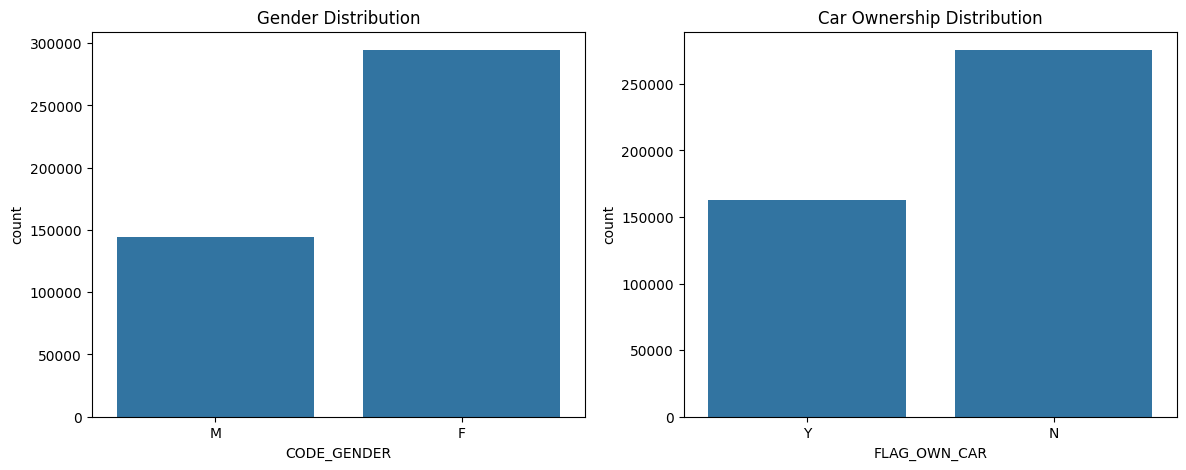

In [37]:
# Summary statistics
display(application_df.describe())

# Distribution of key categorical features
import seaborn as sns
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=application_df, x='CODE_GENDER', ax=axes[0])
axes[0].set_title('Gender Distribution')
sns.countplot(data=application_df, x='FLAG_OWN_CAR', ax=axes[1])
axes[1].set_title('Car Ownership Distribution')
plt.show()

### 4. Overlap Analysis between Datasets

In [38]:
app_ids = set(application_df['ID'])
credit_ids = set(credit_record_df['ID'])
common_ids = app_ids.intersection(credit_ids)

print(f"Unique IDs in Application: {len(app_ids)}")
print(f"Unique IDs in Credit Record: {len(credit_ids)}")
print(f"Common IDs: {len(common_ids)}")

Unique IDs in Application: 438510
Unique IDs in Credit Record: 45985
Common IDs: 36457


In [39]:
missing_count = application_df['OCCUPATION_TYPE'].isnull().sum()
total_count = len(application_df)
missing_percentage = (missing_count / total_count) * 100

print(f"Missing values in 'OCCUPATION_TYPE': {missing_count} out of {total_count} ({missing_percentage:.2f}%)")

Missing values in 'OCCUPATION_TYPE': 134203 out of 438557 (30.60%)


### 6. Label Encoding Categorical Variables

In [40]:
from sklearn.preprocessing import LabelEncoder

# Identify categorical columns
categorical_cols = application_df.select_dtypes(include=['object']).columns.tolist()
print("Categorical columns to be encoded:", categorical_cols)

# Instantiate LabelEncoder and store maps
label_encoders = {}

for col in categorical_cols:
    le = LabelEncoder()
    application_df[col] = le.fit_transform(application_df[col].astype(str))
    label_encoders[col] = le
    print(f"Encoded '{col}' successfully. Classes: {list(le.classes_)}")

# Display the top 5 rows after label encoding
display(application_df.head())

Categorical columns to be encoded: ['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'OCCUPATION_TYPE']
Encoded 'CODE_GENDER' successfully. Classes: ['F', 'M']
Encoded 'FLAG_OWN_CAR' successfully. Classes: ['N', 'Y']
Encoded 'FLAG_OWN_REALTY' successfully. Classes: ['N', 'Y']
Encoded 'NAME_INCOME_TYPE' successfully. Classes: ['Commercial associate', 'Pensioner', 'State servant', 'Student', 'Working']
Encoded 'NAME_EDUCATION_TYPE' successfully. Classes: ['Academic degree', 'Higher education', 'Incomplete higher', 'Lower secondary', 'Secondary / secondary special']
Encoded 'NAME_FAMILY_STATUS' successfully. Classes: ['Civil marriage', 'Married', 'Separated', 'Single / not married', 'Widow']
Encoded 'NAME_HOUSING_TYPE' successfully. Classes: ['Co-op apartment', 'House / apartment', 'Municipal apartment', 'Office apartment', 'Rented apartment', 'With parents']
Encoded 'OCCUPATION_TYPE' successfully. Clas

,ID,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS
0,5008804,1,1,1,0,427500.0,4,1,0,4,-12005,-4542,1,1,0,0,18,2.0
1,5008805,1,1,1,0,427500.0,4,1,0,4,-12005,-4542,1,1,0,0,18,2.0
2,5008806,1,1,1,0,112500.0,4,4,1,1,-21474,-1134,1,0,0,0,16,2.0
3,5008808,0,0,1,0,270000.0,0,4,3,1,-19110,-3051,1,0,1,1,14,1.0
4,5008809,0,0,1,0,270000.0,0,4,3,1,-19110,-3051,1,0,1,1,14,1.0


### 7. Label Encoding for Credit Record Dataset

In [41]:
# Identify categorical columns in credit record dataset
credit_categorical_cols = credit_record_df.select_dtypes(include=['object']).columns.tolist()
print("Categorical columns in credit_record_df:", credit_categorical_cols)

# Instantiate LabelEncoder for credit dataset columns
for col in credit_categorical_cols:
    le = LabelEncoder()
    credit_record_df[col] = le.fit_transform(credit_record_df[col].astype(str))
    label_encoders[f'credit_{col}'] = le
    print(f"Encoded credit '{col}' successfully. Classes: {list(le.classes_)}")

# Display the top 5 rows of credit_record_df after encoding
display(credit_record_df.head())

Categorical columns in credit_record_df: ['STATUS']
Encoded credit 'STATUS' successfully. Classes: ['0', '1', '2', '3', '4', '5', 'C', 'X']


,ID,MONTHS_BALANCE,STATUS
0,5001711,0,7
1,5001711,-1,0
2,5001711,-2,0
3,5001711,-3,0
4,5001712,0,6


### 8. Merging Datasets and Defining X and y
First, we aggregate the credit records for each client. We define a target label `is_bad` where a client is marked as `1` (risky borrower) if they have had status 2, 3, 4, or 5 (representing late payments over 60 days) at any point, and `0` otherwise.

In [42]:
# We construct the target from credit_record_df
# Classes in credit_STATUS mapping order:
# '0': 0, '1': 1, '2': 2, '3': 3, '4': 4, '5': 5, 'C': 6, 'X': 7
# Statuses 2, 3, 4, 5 represent defaults of 60 days or more.
credit_record_df['is_bad'] = credit_record_df['STATUS'].isin([2, 3, 4, 5]).astype(int)

# Aggregate per customer ID (if any month they were 'bad', they are marked as 1)
customer_target = credit_record_df.groupby('ID')['is_bad'].max().reset_index()

# Merge the target with the application features
merged_df = pd.merge(application_df, customer_target, on='ID', how='inner')

# Define X (features) and y (target)
X = merged_df.drop(columns=['ID', 'is_bad'])
y = merged_df['is_bad']

print(f"Merged DataFrame Shape: {merged_df.shape}")
print(f"Features (X) Shape: {X.shape}")
print(f"Target (y) Shape: {y.shape}")
print("\nTarget Class Distribution:")
print(y.value_counts(normalize=True))

Merged DataFrame Shape: (36457, 19)
Features (X) Shape: (36457, 17)
Target (y) Shape: (36457,)

Target Class Distribution:
is_bad
0    0.983103
1    0.016897
Name: proportion, dtype: float64


### 9. Train-Test Split
Now we perform the train-test split using standard stratification on our target variable `y`.

In [43]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")

X_train shape: (29165, 17)
X_test shape: (7292, 17)


In [44]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score, average_precision_score, classification_report, confusion_matrix

tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=6,
    min_samples_leaf=50,
    class_weight="balanced",
    random_state=42)

tree.fit(X_train, y_train)

DecisionTreeClassifier(class_weight='balanced', max_depth=6,
                       min_samples_leaf=50, random_state=42)

In [45]:
proba = tree.predict_proba(X_test)[:, 1]
pred  = tree.predict(X_test)

print("ROC-AUC:", roc_auc_score(y_test, proba))
print("PR-AUC :", average_precision_score(y_test, proba), "(compare with bad rate:", y_test.mean(), ")")
print(confusion_matrix(y_test, pred))
print(classification_report(y_test, pred))

ROC-AUC: 0.5696897323276482
PR-AUC : 0.02595746888660776 (compare with bad rate: 0.01686780032912781 )
[[5490 1679]
 [  79   44]]
              precision    recall  f1-score   support

           0       0.99      0.77      0.86      7169
           1       0.03      0.36      0.05       123

    accuracy                           0.76      7292
   macro avg       0.51      0.56      0.45      7292
weighted avg       0.97      0.76      0.85      7292



### 10. Testing the Model with a New Custom Input
Let's create a hypothetical applicant profile, ensure the features map to our encoded dataset structure, and predict the credit risk.

In [46]:
import pandas as pd
import numpy as np

# Create a dictionary representing a new customer with the correct column names
# We use typical values matching the encoded features of X
new_customer = {
    'CODE_GENDER': 0,          # Female (0)
    'FLAG_OWN_CAR': 0,         # No (0)
    'FLAG_OWN_REALTY': 1,      # Yes (1)
    'CNT_CHILDREN': 0,
    'AMT_INCOME_TOTAL': 150000.0,
    'NAME_INCOME_TYPE': 4,     # Working (4)
    'NAME_EDUCATION_TYPE': 4,  # Secondary / secondary special (4)
    'NAME_FAMILY_STATUS': 1,   # Married (1)
    'NAME_HOUSING_TYPE': 1,    # House / apartment (1)
    'DAYS_BIRTH': -15000,      # ~41 years old
    'DAYS_EMPLOYED': -2000,    # ~5.5 years employed
    'FLAG_MOBIL': 1,
    'FLAG_WORK_PHONE': 0,
    'FLAG_PHONE': 1,
    'FLAG_EMAIL': 0,
    'OCCUPATION_TYPE': 17,     # Unknown (17)
    'CNT_FAM_MEMBERS': 2.0
}

# Convert to DataFrame
new_input_df = pd.DataFrame([new_customer], columns=X.columns)

# Predict using our trained Decision Tree model
predicted_class = tree.predict(new_input_df)[0]
predicted_probability = tree.predict_proba(new_input_df)[0, 1]

print("=== Testing New Input ===")
print(f"Predicted Class: {predicted_class} ({'Bad/High Risk' if predicted_class == 1 else 'Good/Low Risk'})")
print(f"Probability of being a Bad Risk: {predicted_probability:.4f}")

=== Testing New Input ===
Predicted Class: 0 (Good/Low Risk)
Probability of being a Bad Risk: 0.4624


In [47]:
from sklearn.metrics import roc_auc_score, average_precision_score

for name, X_, y_ in [("Train", X_train, y_train), ("Test", X_test, y_test)]:
    p = tree.predict_proba(X_)[:, 1]
    print(f"{name:5s}  ROC-AUC: {roc_auc_score(y_, p):.3f}   PR-AUC: {average_precision_score(y_, p):.3f}")

Train  ROC-AUC: 0.705   PR-AUC: 0.045
Test   ROC-AUC: 0.570   PR-AUC: 0.026


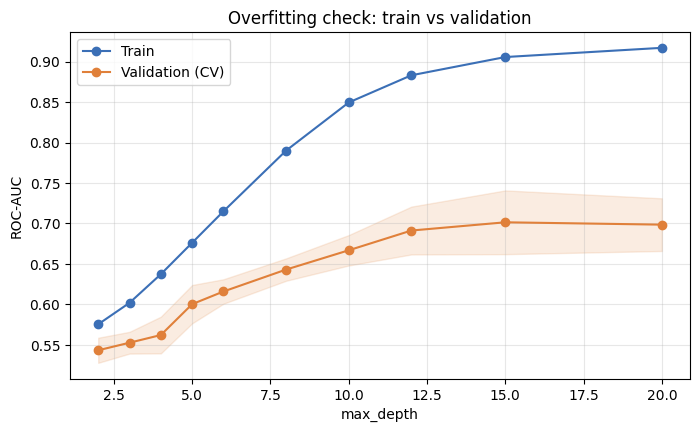

Best max_depth by validation ROC-AUC: 15
depth  2  train 0.576  val 0.543  gap +0.032
depth  3  train 0.602  val 0.553  gap +0.049
depth  4  train 0.637  val 0.562  gap +0.075
depth  5  train 0.676  val 0.600  gap +0.076
depth  6  train 0.715  val 0.616  gap +0.099
depth  8  train 0.790  val 0.643  gap +0.147
depth 10  train 0.849  val 0.667  gap +0.183
depth 12  train 0.883  val 0.691  gap +0.192
depth 15  train 0.906  val 0.701  gap +0.204
depth 20  train 0.917  val 0.699  gap +0.218


In [48]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import validation_curve, StratifiedKFold

depths = [2, 3, 4, 5, 6, 8, 10, 12, 15, 20]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

train_scores, val_scores = validation_curve(
    DecisionTreeClassifier(criterion="gini", min_samples_leaf=50,
                           class_weight="balanced", random_state=42),
    X_train, y_train,
    param_name="max_depth", param_range=depths,
    scoring="roc_auc", cv=cv, n_jobs=-1)

train_mean, val_mean = train_scores.mean(axis=1), val_scores.mean(axis=1)
val_std = val_scores.std(axis=1)

plt.figure(figsize=(8, 4.5))
plt.plot(depths, train_mean, marker="o", color="#3b6fb6", label="Train")
plt.plot(depths, val_mean, marker="o", color="#e0803a", label="Validation (CV)")
plt.fill_between(depths, val_mean - val_std, val_mean + val_std, color="#e0803a", alpha=0.15)
plt.xlabel("max_depth"); plt.ylabel("ROC-AUC")
plt.title("Overfitting check: train vs validation")
plt.legend(); plt.grid(alpha=0.3); plt.show()

best = depths[int(np.argmax(val_mean))]
print("Best max_depth by validation ROC-AUC:", best)
for d, t, v in zip(depths, train_mean, val_mean):
    print(f"depth {d:2d}  train {t:.3f}  val {v:.3f}  gap {t - v:+.3f}")

In [49]:
print("Rows identical to another row (ignoring ID):", X.duplicated().sum(), "of", len(X))

Rows identical to another row (ignoring ID): 26729 of 36457


In [50]:
from sklearn.model_selection import GroupKFold, validation_curve

# one group id per unique set of feature values, so copies always stay together
groups_all = X.groupby(list(X.columns)).ngroup()
groups_train = groups_all.loc[X_train.index]

train_scores, val_scores = validation_curve(
    DecisionTreeClassifier(criterion="gini", min_samples_leaf=50,
                           class_weight="balanced", random_state=42),
    X_train, y_train, groups=groups_train,
    param_name="max_depth", param_range=depths,
    scoring="roc_auc", cv=GroupKFold(n_splits=5), n_jobs=-1)

for d, t, v in zip(depths, train_scores.mean(axis=1), val_scores.mean(axis=1)):
    print(f"depth {d:2d}  train {t:.3f}  val {v:.3f}  gap {t - v:+.3f}")

depth  2  train 0.573  val 0.512  gap +0.061
depth  3  train 0.607  val 0.525  gap +0.082
depth  4  train 0.638  val 0.510  gap +0.129
depth  5  train 0.678  val 0.530  gap +0.148
depth  6  train 0.717  val 0.539  gap +0.179
depth  8  train 0.791  val 0.562  gap +0.230
depth 10  train 0.843  val 0.563  gap +0.279
depth 12  train 0.881  val 0.565  gap +0.316
depth 15  train 0.912  val 0.567  gap +0.345
depth 20  train 0.925  val 0.566  gap +0.359


In [51]:
from sklearn.model_selection import GroupShuffleSplit
gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
tr_idx, te_idx = next(gss.split(X, y, groups=groups_all))
X_train, X_test = X.iloc[tr_idx], X.iloc[te_idx]
y_train, y_test = y.iloc[tr_idx], y.iloc[te_idx]

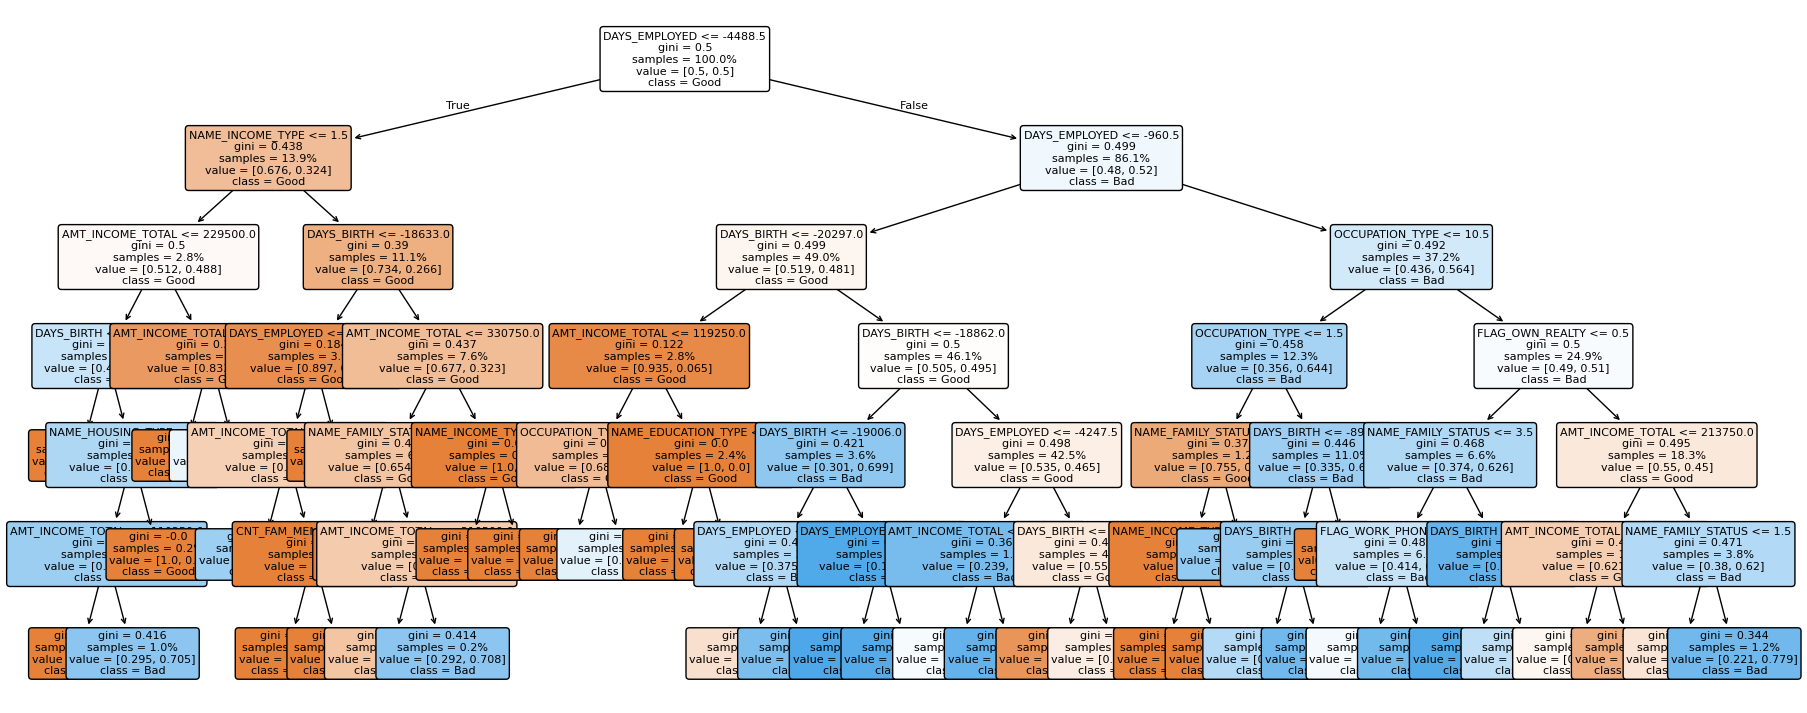

In [53]:
plt.figure(figsize=(22, 9))
plot_tree(tree, feature_names=X.columns, class_names=["Good", "Bad"],
          filled=True, rounded=True, fontsize=8, proportion=True)
plt.show()

In [54]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Initialize the Decision Tree Regressor
# We'll set a max_depth to avoid extreme overfitting and a minimum sample split criterion
regressor = DecisionTreeRegressor(
    max_depth=6,
    min_samples_leaf=50,
    random_state=42
)

# Fit the regressor on the training data
regressor.fit(X_train, y_train)

# Predict on training and test sets
y_train_pred = regressor.predict(X_train)
y_test_pred = regressor.predict(X_test)

# Evaluate using regression metrics
print("=== Train Regression Performance ===")
print(f"MSE : {mean_squared_error(y_train, y_train_pred):.5f}")
print(f"MAE : {mean_absolute_error(y_train, y_train_pred):.5f}")
print(f"R²  : {r2_score(y_train, y_train_pred):.5f}")

print("\n=== Test Regression Performance ===")
print(f"MSE : {mean_squared_error(y_test, y_test_pred):.5f}")
print(f"MAE : {mean_absolute_error(y_test, y_test_pred):.5f}")
print(f"R²  : {r2_score(y_test, y_test_pred):.5f}")

=== Train Regression Performance ===
MSE : 0.01675
MAE : 0.03351
R²  : 0.01844

=== Test Regression Performance ===
MSE : 0.01514
MAE : 0.03262
R²  : -0.02493


In [55]:
# Create the same mock applicant profile we defined for testing before
new_customer_reg = {
    'CODE_GENDER': 0,          # Female (0)
    'FLAG_OWN_CAR': 0,         # No (0)
    'FLAG_OWN_REALTY': 1,      # Yes (1)
    'CNT_CHILDREN': 0,
    'AMT_INCOME_TOTAL': 150000.0,
    'NAME_INCOME_TYPE': 4,     # Working (4)
    'NAME_EDUCATION_TYPE': 4,  # Secondary / secondary special (4)
    'NAME_FAMILY_STATUS': 1,   # Married (1)
    'NAME_HOUSING_TYPE': 1,    # House / apartment (1)
    'DAYS_BIRTH': -15000,      # ~41 years old
    'DAYS_EMPLOYED': -2000,    # ~5.5 years employed
    'FLAG_MOBIL': 1,
    'FLAG_WORK_PHONE': 0,
    'FLAG_PHONE': 1,
    'FLAG_EMAIL': 0,
    'OCCUPATION_TYPE': 17,     # Unknown (17)
    'CNT_FAM_MEMBERS': 2.0
}

# Convert to DataFrame with columns in the exact order as X
new_input_reg_df = pd.DataFrame([new_customer_reg], columns=X.columns)

# Make a continuous prediction using our Decision Tree Regressor
predicted_score = regressor.predict(new_input_reg_df)[0]

print("=== Regressor Inference Test ===")
print(f"Predicted Continuous Score (representing raw default likelihood): {predicted_score:.5f}")

=== Regressor Inference Test ===
Predicted Continuous Score (representing raw default likelihood): 0.01710


In [56]:
# Print the predicted value directly
print(f"Predicted value: {predicted_score:.5f}")

Predicted value: 0.01710


In [57]:
print("=== Classifier Prediction Output ===")
print(f"Predicted Class: {predicted_class} ({'Bad/High Risk' if predicted_class == 1 else 'Good/Low Risk'})")
print(f"Probability of being a Bad Risk: {predicted_probability:.4f} ({predicted_probability * 100:.2f}%)")

=== Classifier Prediction Output ===
Predicted Class: 0 (Good/Low Risk)
Probability of being a Bad Risk: 0.4624 (46.24%)


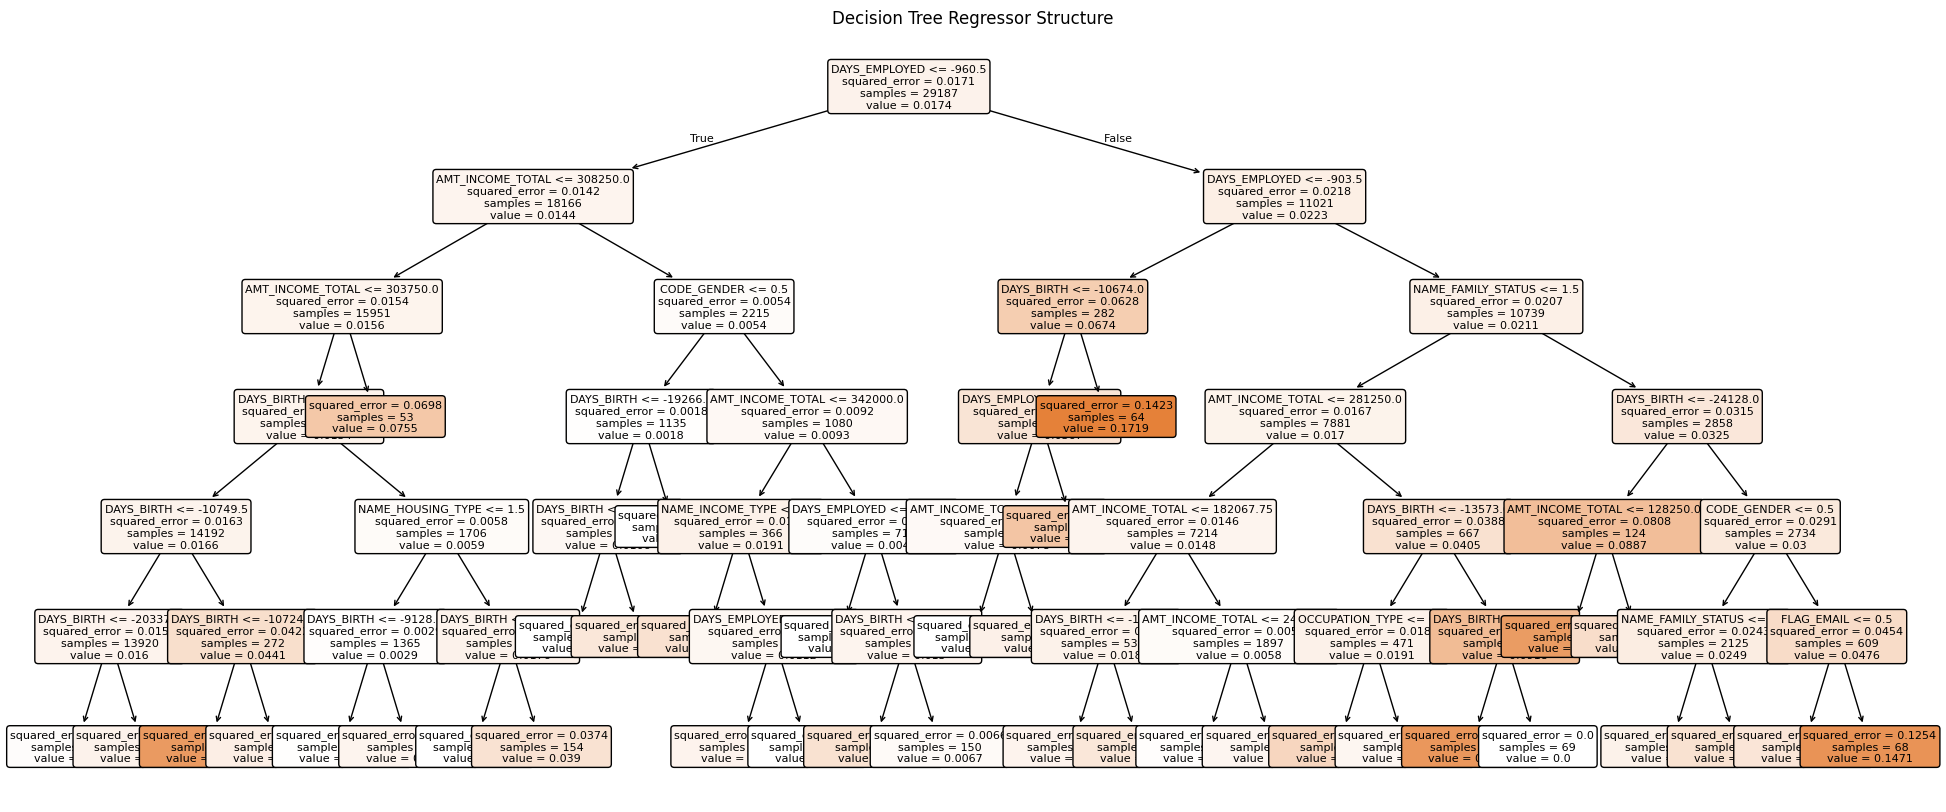

In [58]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

# Configure the figure size for a detailed view
plt.figure(figsize=(24, 10))

# Plot the regressor tree
plot_tree(
    regressor,
    feature_names=X.columns,
    filled=True,
    rounded=True,
    fontsize=8,
    precision=4
)

plt.title("Decision Tree Regressor Structure")
plt.show()